In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import scipy.optimize as sol
import scipy.integrate as integrate
#from numba import jit

In [2]:
class cell:
    def __init__(self,index,init_clusters,parent,birth,tau):
        '''Initializes cell attributes
        param:: index: cell index
        param:: clusters: count of n-clusters
        param:: x: plasmid trajectory in time 
        param:: t: time stamps for x
        param:: parent: parent cell
        param:: birth: birth time
        return:: None
        '''
        self.index=index
        self.init_clusters=init_clusters
        self.fin_clusters=[]
        self.x = []
        self.t = []
        self.parent = parent
        self.birth = birth
        self.div = birth+tau+np.random.normal(0,1)

#@jit
def find_tot_plasmids(y1,y2,max_size):
    y1[0]+=y1[1]   #because of plasmid shedding y[1] may have a nonzero value, we transfer this to y[0].
    y2[0]+=y2[1]
    y1[1]=y1[0]
    y2[1]=y2[0]
    y_tot1 = np.dot(np.arange(1,max_size),y1[1:max_size])
    y_tot2 = np.dot(np.arange(1,max_size),y2[1:max_size])            
    y_tot = y_tot1+y_tot2
    y1[1]=0
    y2[1]=0
    return y1,y2,y_tot1,y_tot2,y_tot 

#@jit
def pop_check(cells,T):
    b_filter = [x for x in cells if x.t[0] <= T]
    d_filter = [x for x in b_filter if x.t[-1] >T]
    return d_filter #N_pop

#@jit

def hazards(y,c_idx,num_reax,N,beta,gamma,sigma,max_size,t_f):  #remove y_tot, y_totp
    #def hazards(y,c_idx,num_reax,N,y_totp,y_tot,beta,gamma,sigma,max_size,t_f):  #remove y_tot, y_totp
    a = np.zeros(num_reax)                                     #reaction hazards 
    v = np.zeros([num_reax,max_size])                           #reaction vectors    
    #V = V0*np.exp(mu*t_f)
    a[0]= 1 #(k_tr*y_totp)/(1+K*y_tot/(s0*6.022e2*n*V))**n    #not needed since computation of reaction time is different 
    v[0,0] = 1
    a[1] = 0.5*beta*y[0]*(y[0]-1)
    v[1,0] = -2
    v[1,2] = 1
    
    if N>1:
        species_idx =np.zeros([2,num_reax])
        count=1
        for i in np.arange(1,N):   #plasmid recruitment
            count+=1
            a[count] = beta*y[0]*y[c_idx[i]]
            species_idx[:,count] = np.array([c_idx[i],0])
        rec_count=count
                
        for i in np.arange(1,N):   #cluster combination
            for j in np.arange(i,N):
                count+=1
                if i==j:
                    a[count] = 0.5*gamma*y[c_idx[i]]*(y[c_idx[j]]-1)
                else:
                    a[count] = gamma*y[c_idx[i]]*y[c_idx[j]]
                species_idx[:,count] = [c_idx[i],c_idx[j]]
        cluster_count = count
            
        for i in np.arange(1,N): #plasmid shedding
            count+=1
            a[count] = sigma*y[c_idx[i]]*c_idx[i]
            species_idx[:,count] = np.array([c_idx[i],0])
                    
        for i in range(len(a)): #reaction vectors
            if i==0:                         #plasmid replication
                v[i,0] = 1
            elif i==1:                       #plasmid duplex formation
                v[i,0] = -2
                v[i,2] = 1
            elif (2<=i and i<=rec_count):    #plasmid recruitment to a cluster
                v[i,0] = -1
                v[i,int(species_idx[0,i])] = -1
                v[i,int(species_idx[0,i])+1] = 1
            elif (i>rec_count and i<=cluster_count):   #cluster combination

                if (int(species_idx[0,i])==int(species_idx[1,i]) and y[int(species_idx[1,i])]>1 ):
                    #if np.sum(species_idx[:,i])>50:
                        #print(species_idx[:,i],int(np.sum(species_idx[:,i])))
                        #print(y)
                    v[i,int(species_idx[0,i])] = -2
                    v[i,int(np.sum(species_idx[:,i]))] = 1
                elif not(int(species_idx[0,i])==int(species_idx[1,i])):
                    #if np.sum(species_idx[:,i])>50:
                        #print(species_idx[:,i],int(np.sum(species_idx[:,i])))
                        #print(y)
                    v[i,int(species_idx[0,i])] = -1
                    v[i,int(species_idx[1,i])] = -1
                    v[i,int(np.sum(species_idx[:,i]))] = 1
            else:                            #plasmid shedding         
                v[i,0] = 1
                v[i,int(species_idx[0,i])] = -1
                v[i,int(species_idx[0,i])-1] = 1   
    return a,v



#@jit
def mnrn(y0,x0,tau,beta,gamma,sigma,max_size):
    y=y0               #plasmid count count; y[0]=x[0], y[1]=0, y[i] = number of cluster of size i     
    x=[x0]
    t_x = [0]
    t_y=0             #reaction time 
    y_tot1=x0
    y_tot2 = 0
    y1 = y[:max_size]
    y2 = y[max_size:2*max_size] 
    y_tot=y_tot1+y_tot2
    while t_y<tau:
        ############################### pole 1 ##################################    
        dummy = y1[0]                                               
        y1[0] = 1
        c_idx1 = np.where(y1>0)[0]                                  #indices of species with non-zero state except possibly free plasmids
        y1[0] = dummy
        N1 = len(c_idx1)                                            #number of non-zero species
        num_reax1 = N1+1+int(((N1-1)**2-N1+1)/2)+2*(N1-1)           #possible number of reactions given the system state 
        a1,v1 = hazards(y1,c_idx1,num_reax1,N1,beta,gamma,sigma,max_size,t_y)     
        
        ############################### pole 2 ##################################
        dummy = y2[0]
        y2[0]=1
        c_idx2 = np.where(y2>0)[0]                                  
        y2[0]=dummy
        N2 = len(c_idx2)
        num_reax2 = N2+1+int(((N2-1)**2-N2+1)/2)+2*(N2-1)  
        a2,v2 = hazards(y2,c_idx2,num_reax2,N2,beta,gamma,sigma,max_size,t_y)
 
        a = np.append(a1,a2,axis=0)
        a = np.append(a,[rho*y1[0],rho*y2[0]])
        epsilon=np.random.uniform(0,1,len(a))
        t_j  = np.zeros(num_reax1+num_reax2+2)
        
        for i in range(len(a)):
            if i == 0:
                t_j[i] = sol.fsolve(func,0.1,args=(t_y,y_tot1,epsilon[i],y_tot)) 
            elif i == num_reax1:
                t_j[i] = sol.fsolve(func,0.1,args=(t_y,y_tot2,epsilon[i],y_tot)) 
            else:
                if a[i]==0:
                    t_j[i] = np.inf
                else:
                    t_j[i] = -np.log(epsilon[i])/a[i]
        #print(t_j)
        j=np.argmin(t_j)
        if (j==num_reax1+num_reax2):
            y2[0]+=1
            y1[0]-=1
        elif (j==num_reax1+num_reax2+1):
            y2[0]-=1
            y1[0]+=1
        elif (num_reax1<=j and j<num_reax1+num_reax2):
            y2+=v2[j-num_reax1,:]  
        else:
            y1+=v1[j,:]    

        y1,y2,y_tot1,y_tot2,y_tot = find_tot_plasmids(y1,y2,max_size)
        if (j==0 or j==num_reax1):
            x= np.append(x,y_tot)
            t_x =np.append(t_x,[t_y])
        t_y+=t_j[j]      
        
        #print(j,x[-1],t_y)
    y = np.append(y1,y2,axis=0)
    return y,x,t_x

def func(w,tx,xi,eps,y_tot):
    return integrate.quad(integrand, tx, tx+w, args =(xi,y_tot))[0] + np.log(eps)

def integrand(s,xi,y_tot):
    V= V0*np.exp(s*mu)
    return (k_tr*xi)/(1+K*y_tot/(s0*6.022e2*n*V))**n 

#@jit
def sim_cells(current,beta,gamma,sigma,max_size):
    y0 = current.init_clusters
    y0[1]=y0[0]
    x0 = np.dot(np.arange(1,max_size),y0[1:max_size])
    y0[1]=0 
    if x0>0:
        yy,xx,tt = mnrn(y0,x0,current.div-current.birth,beta,gamma,sigma,max_size)
        #yy,xx,tt = ssa_dt(y0,x0,current.div-current.birth,beta,gamma,sigma,max_size)
    else:
        yy = y0
        xx = np.array([0,0])
        tt = np.array([0,current.div-current.birth])
    return yy,xx,tt


def lineage_sim(c,tau,beta,gamma,sigma,max_size):
    Line=[]
    current_cell = c 
    N=0
    status =1
    while status == 1:
        yy,xx,tt = sim_cells(current_cell,beta,gamma,sigma,max_size)
        #update current cell
        current_cell.fin_clusters = yy
        current_cell.x = xx
        current_cell.t = tt+current_cell.birth   
        Line.extend([current_cell])
        if np.random.uniform(0,1)<0.5:
            daughter = cell(N+1,np.append(yy[:max_size],np.zeros(max_size)),current_cell.index,current_cell.t[-1],tau)
        else:
            daughter = cell(N+1,np.append(yy[max_size:],np.zeros(max_size)),current_cell.index,current_cell.t[-1],tau)
        
        x0 = np.dot(np.arange(1,max_size),daughter.init_clusters[1:max_size])
        if current_cell.x[-1]==x0 or x0==0 or len(Line)==1:
            status = 0
        else:
            status = 1
            current_cell = daughter
            N+=1
    return Line

In [3]:
##################################################
n =2.5540
s0 = 0.1675/n  
tau = 60             #60-min doubling time
k_tr = 2.73       
K = 11.35/1.26  
mu = np.log(2)/tau
scale = 0.54
V0 = 0.48*scale
##################################################

x0=20          #number of plasmids in the initial cell
max_size=100   #total number of possible clusters, can be increased to accomodate larger sims

########################### modify this for simulations ###############################
beta = 0.25 #plasmid recruitment rate constant
gamma = 0.05 #plasmid combination rate constant
sigma= 0.08  #plasmid dissociation rate constant
rho = 0.1  #plasmid transfer rate constant

In [4]:
y0 = np.zeros(2*max_size)
y0[0]=x0
c= cell(0,y0,[],0,tau)
Line = lineage_sim(c,tau,beta,gamma,sigma,max_size)

C:\Users\Jayson Cortez\anaconda3\lib\site-packages\scipy\optimize\_minpack_py.py:178: RuntimeWarning: The iteration is not making good progress, as measured by the 
  improvement from the last ten iterations.
  warnings.warn(msg, RuntimeWarning)


In [6]:
summ=0
for i in range(len(Line)):
    print(Line[i].x[-1])
    summ+=Line[i].x[-1]
print('ave:',summ/len(Line))

44.0
ave: 44.0


In [9]:
repeats = 50
thresh=6
g = np.zeros([repeats,5])
prob_loss_v = np.zeros(repeats)
free_v = np.zeros(repeats)
for i in range(repeats):
    y0 = np.zeros(2*max_size)
    y0[0]=x0
    c= cell(0,y0,[],0,tau)   #index,clusters,parent,birth
    cells = lineage_sim(c,tau,beta,gamma,sigma,max_size)
    cluster_num = np.zeros(len(cells))
    loss_count = 0
    free = np.zeros(len(cells))
    
    for j in range(len(cells)):
        yy = cells[j].fin_clusters    #final count of clusters of cell j in the lineage
        cluster_num[j] = np.sum(yy[thresh:max_size])+np.sum(yy[max_size+thresh:])  #number of clusters of cell j in the lineage
        free[j] = (yy[0]+yy[max_size])/cells[j].x[-1]     #fraction of mobile plasmid at cell j in the lineage
    free_v[i] = np.mean(free)
    prob_loss_v[i] = 1./len(cells)
        
    height = np.bincount(cluster_num.astype(int))/len(cluster_num)
    dummy=np.sum(height[4:])
    heights=np.zeros(5)
    if len(height)>4:
        height[4]=dummy
        heights = np.delete(height,np.arange(5,len(height)))
    else:
        heights[:len(height)]=height
    g[i,:]=heights
    print('dist:',heights,'loss:',prob_loss_v[i],'mobile:',free_v[i])
    
#print(summ/repeats)  #arrival rate of plasmid free cell (cells/min)
print('ave mobile cells fraction',np.mean(free_v))
print('ave plasmid-free cells fraction',np.mean(prob_loss_v))
print('cluster distribution',np.mean(g,axis=0))

columns=' '
np.savetxt("cluster_dist.csv", g, delimiter=",",header=columns)
np.savetxt("mobile_prob.csv", free_v, delimiter=",",header=columns)
np.savetxt("loss_prob.csv", prob_loss_v, delimiter=",",header=columns)


dist: [0. 0. 1. 0. 0.] loss: 1.0 mobile: 0.11627906976744186
dist: [0. 1. 0. 0. 0.] loss: 1.0 mobile: 0.06521739130434782
dist: [0. 0. 0. 1. 0.] loss: 1.0 mobile: 0.05
dist: [0. 0. 1. 0. 0.] loss: 1.0 mobile: 0.08695652173913043
dist: [0. 0. 1. 0. 0.] loss: 1.0 mobile: 0.044444444444444446
dist: [0. 0. 0. 1. 0.] loss: 1.0 mobile: 0.022222222222222223
dist: [0. 0. 0. 0. 1.] loss: 1.0 mobile: 0.04
dist: [0. 0. 0. 1. 0.] loss: 1.0 mobile: 0.14893617021276595
dist: [0. 0. 1. 0. 0.] loss: 1.0 mobile: 0.045454545454545456
dist: [0. 0. 1. 0. 0.] loss: 1.0 mobile: 0.06976744186046512
dist: [0. 0. 0. 1. 0.] loss: 1.0 mobile: 0.04081632653061224
dist: [0. 1. 0. 0. 0.] loss: 1.0 mobile: 0.07894736842105263
dist: [0. 0. 1. 0. 0.] loss: 1.0 mobile: 0.05128205128205128
dist: [0. 0. 0. 1. 0.] loss: 1.0 mobile: 0.06382978723404255
dist: [0. 0. 1. 0. 0.] loss: 1.0 mobile: 0.06976744186046512
dist: [0. 0. 0. 1. 0.] loss: 1.0 mobile: 0.07894736842105263
dist: [0. 0. 1. 0. 0.] loss: 1.0 mobile: 0.06976744

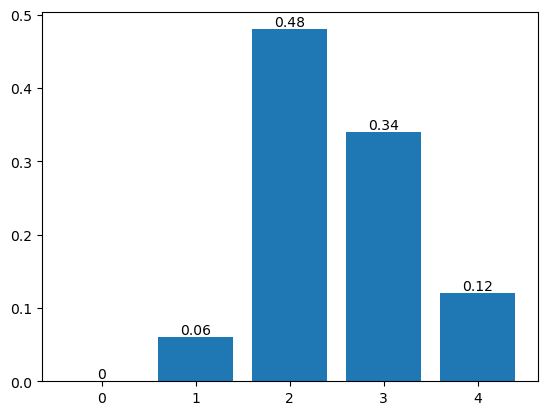

In [12]:
fig, ax = plt.subplots()
ax.bar([0,1,2,3,4],np.mean(g,axis=0))
for bars in ax.containers:
    ax.bar_label(bars)

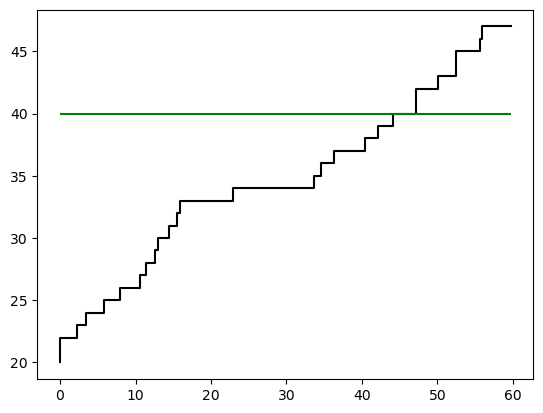

In [10]:
for i in range(len(cells)):
    plt.step(cells[i].t,cells[i].x,color='k')
    if i<len(cells)-1:
        plt.vlines(cells[i].t[-1],cells[i+1].x[0],cells[i].x[-1],color='red')
plt.hlines(40,0,cells[-1].t[-1],color='green')


In [ ]:
def reject_outliers(data, m=2):
    return data[abs(data - np.mean(data)) < m * np.std(data)]

print(np.mean(reject_outliers(prob_loss_v,2)))
print(np.std(reject_outliers(prob_loss_v,2)))

In [ ]:
columns=' '
np.savetxt("cluster_dist.csv", g, delimiter=",",header=columns)
np.savetxt("mobile_prob.csv", free_v, delimiter=",",header=columns)
np.savetxt("loss_prob.csv", prob_loss_v, delimiter=",",header=columns)


In [ ]:
print(np.mean(reject_outliers(free_v,2)))
print(np.std(reject_outliers(free_v,2)))

In [ ]:
#@jit
def mnrn(y0,x0,tau,beta,gamma,sigma,max_size):
    y=y0               #plasmid count count; y[0]=x[0], y[1]=0, y[i] = number of cluster of size i     
    x=[x0]
    t_x = [0]
    t_y=0             #reaction time 
    y_tot1=x0
    y_tot2 = 0
    y1 = y[:max_size]
    y2 = y[max_size:2*max_size] 
    y_tot=y_tot1+y_tot2
    while t_y<tau:
        ############################### pole 1 ##################################    
        dummy = y1[0]                                               
        y1[0] = 1
        c_idx1 = np.where(y1>0)[0]                                  #indices of species with non-zero state except possibly free plasmids
        y1[0] = dummy
        N1 = len(c_idx1)                                            #number of non-zero species
        num_reax1 = N1+1+int(((N1-1)**2-N1+1)/2)+2*(N1-1)           #possible number of reactions given the system state 
        a1,v1 = hazards(y1,c_idx1,num_reax1,N1,y_tot1,y_tot,beta,gamma,sigma,max_size,t_y)     
        
        ############################### pole 2 ##################################
        dummy = y2[0]
        y2[0]=1
        c_idx2 = np.where(y2>0)[0]                                  
        y2[0]=dummy
        N2 = len(c_idx2)
        num_reax2 = N2+1+int(((N2-1)**2-N2+1)/2)+2*(N2-1)  
        a2,v2 = hazards(y2,c_idx2,num_reax2,N2,y_tot2,y_tot,beta,gamma,sigma,max_size,t_y)
 
        a = np.append(a1,a2,axis=0)
        a = np.append(a,[rho*y1[0],rho*y2[0]])
        epsilon=np.random.uniform(0,1,len(a))
        t_j  = np.zeros(num_reax1+num_reax2+2)
        
        for i in range(len(a)):
            if i == 0:
                t_j[i] = sol.fsolve(func,0.01,args=(t_y,y_tot1,epsilon[i],y_tot)) 
            elif i == num_reax1:
                t_j[i] = sol.fsolve(func,0.01,args=(t_y,y_tot1,epsilon[i],y_tot)) 
            else:
                if a[i]==0:
                    t_j[i] = np.inf
                else:
                    t_j[i] = -np.log(epsilon[i])/a[i]
        #print(t_j)
        j=np.argmin(t_j)
            
        if (j==num_reax1+num_reax2):
            y2[0]+=1
            y1[0]-=1
        elif (j==num_reax1+num_reax2+1):
            y2[0]-=1
            y1[0]+=1
        elif (num_reax1<=j and j<num_reax1+num_reax2):
            y2+=v2[j-num_reax1,:]  
        else:
            y1+=v1[j,:]    

        y1,y2,y_tot1,y_tot2,y_tot = find_tot_plasmids(y1,y2,max_size)
        if (j==0 or j==num_reax1):
            x= np.append(x,y_tot)
            t_x =np.append(t_x,[t_y])
        t_y+=t_j[j]      
        
        #print(j,x[-1],t_y)
    y = np.append(y1,y2,axis=0)
    return y,x,t_x


In [ ]:
f(16/12)